In [1]:
# 导入torchvision,用于处理图像和视频，转换成张量
from torchvision.transforms import ToTensor
import torchvision
import torch
import torch.nn as nn

In [2]:
# 加载数据集pytorch本身提供了经典的手写数据集
# 加载训练集
train_ds = torchvision.datasets.MNIST(
    'data/',
    # 指定加载训练集
    train=True,
    # 将图像，numpy转换为tensor
    transform=ToTensor(),
    download=True
)

In [3]:
# 加载测试训练集
test_ds = torchvision.datasets.MNIST(
    'data/',
    # 指定加载训练集
    train=False,
    # 将图像，numpy转换为tensor
    transform=ToTensor(),
    download=True
)

In [4]:
# 指定训练数据加载器
train_dl = torch.utils.data.DataLoader(
    train_ds,
    batch_size=64,
    # 提高模型泛化能力
    shuffle=True# 每轮epoch打乱样本顺序
)

test_dl = torch.utils.data.DataLoader(
    test_ds,
    batch_size=256,
    # 提高模型泛化能力
    shuffle=True
)

In [5]:
train_dl

In [6]:
imgs,labels=next(iter(train_dl))

In [7]:
imgs.shape

torch.Size([64, 1, 28, 28])

In [8]:
img = imgs[0]
# imgs

In [9]:

img = img.numpy()
# 去掉一维
img = img.squeeze()
img.shape

(28, 28)

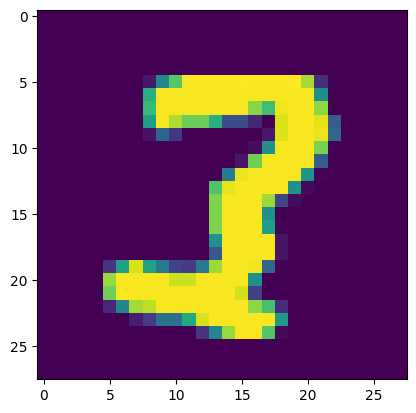

In [10]:
# 转换为可视图
import matplotlib.pyplot as plt
plt.imshow(img)

In [18]:
import torch.nn.functional as F
# 搭建手写识别模型
class Model(nn.Module):
    # 初始化函数定义网络层
    def __init__(self):
        super().__init__()
        # 定义卷积层，输入通道数1，输出通道数6，卷积核大小5
        self.conv1=nn.Conv2d(1,6,5)
        # 定义卷积层，输入通道数6，输出通道数16，卷积核大小5
        self.conv2=nn.Conv2d(6,16,5)

# 原图28*28，卷积核5*5，输出就是28-5+1=24，也就是24*24*6
# 进行池化，步长2*2，变成了12*12*6
# 卷积层2：12-5+1=8,8*8*16
# 进行池化，4*4*16


        
        # 定义一个784个节点的线性层
        self.linear_1 = nn.Linear(16*4*4,120)
        self.linear_2 = nn.Linear(120,10)

    # 定义前向传播函数
    def forward(self,input):
        
        # 将输入到卷积层1
        x=self.conv1(input)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2)
        # 将输入到卷积层2
        x=self.conv2(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2)

        # 将多维立方体的数据转为1维，用于全连接
        x=x.view(-1,16*4*4)

        
        # 将输入给到第一层线性层
        x = self.linear_1(x)
        # 使用relu激活函数
        x = F.relu(x)
        # 将输入给到第二层线性层
        x = self.linear_2(x)
        
     
        # 返回结果
        return x
        


In [19]:
# torch.cuda.is_available()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [20]:
model = Model().to(device)

In [21]:
# 定义损失函数
loss_fn = torch.nn.CrossEntropyLoss()
# 定义优化器
optimizer = torch.optim.SGD(model.parameters(),lr=0.005)

In [22]:
# 定义训练函数，从训练加载器里提取训练数据，进行训练
def train(dataLoader,model,loss_fn,optimizer):
    # 获取整个训练数据集大小
    size = len(dataLoader.dataset)
    train_loss,correct=0,0      
    # 循环遍历整个数据集
    for X,Y in dataLoader:
        X,Y=X.to(device),Y.to(device)
        # 进行初步预测
        pred=model(X)
        # 查看误差
        loss = loss_fn(pred,Y)

        # 梯度归零
        optimizer.zero_grad()
        # 反向传播
        loss.backward()
        # 使用优化器更新参数
        optimizer.step()

        # 计算当前准确率
        # 计算准确率不需要更新梯度
        with torch.no_grad():
            # 在10个数据里挑最大值
            correct += (pred.argmax(1)==Y).type(torch.float).sum().item()
            # 获取当前训练的损失值
            train_loss +=loss.item()
    # 计算平均损失和正确率
    train_loss = train_loss / size
    correct = correct/size
    return train_loss,correct
        

In [23]:
# 定义一个测试函数
def test(dataLoader,model):
    # 获取测试集大小
    size = len(dataLoader.dataset)
    train_loss, correct = 0, 0
     # 计算准确率不需要更新梯度
    with torch.no_grad():
        for X,Y in dataLoader:
            X,Y=X.to(device),Y.to(device)
            # 进行初步预测
            pred=model(X)
            # 查看误差
            loss = loss_fn(pred,Y)
            # 在10个数据里挑最大值
            correct += (pred.argmax(1)==Y).type(torch.float).sum().item()
            # 获取当前训练的损失值
            train_loss +=loss.item()
    # 计算平均损失和正确率
    train_loss = train_loss / size
    correct = correct/size
    return train_loss,correct

In [24]:
# 训练多轮
epochs = 15
train_acc=[]
test_acc=[]
for epoch in range(epochs):
    epoch_loss,epoch_acc = train(train_dl,model,loss_fn,optimizer)
    epoch_test_loss,epoch_test_acc = test(test_dl,model)
    train_acc.append(epoch_acc)
    test_acc.append(epoch_test_acc)
    print('epoch:{},train_loss:{},train_acc{}'.format(epoch,epoch_loss,epoch_acc))
    print('epoch:{},test_loss:{},test_acc{}'.format(epoch,epoch_test_loss,epoch_test_acc))
    print('---------------------------------')

epoch:0,train_loss:0.03345152833263079,train_acc0.35825
epoch:0,test_loss:0.004992220950126648,test_acc0.7035
---------------------------------
epoch:1,train_loss:0.009065555118272702,train_acc0.8374
epoch:1,test_loss:0.0014656627275049685,test_acc0.8889
---------------------------------
epoch:2,train_loss:0.005039869038884839,train_acc0.9034666666666666
epoch:2,test_loss:0.0009689913999289274,test_acc0.9261
---------------------------------
epoch:3,train_loss:0.003746674377533297,train_acc0.9271166666666667
epoch:3,test_loss:0.0008599187158048153,test_acc0.9344
---------------------------------
epoch:4,train_loss:0.0030366747537006935,train_acc0.9406166666666667
epoch:4,test_loss:0.0006144309751689434,test_acc0.9534
---------------------------------
epoch:5,train_loss:0.0025723580146518846,train_acc0.9507833333333333
epoch:5,test_loss:0.0005840459927916526,test_acc0.9561
---------------------------------
epoch:6,train_loss:0.00225898202660804,train_acc0.9563166666666667
epoch:6,test_l

In [39]:
# 保存张量
a = torch.arange(4)
torch.save(a,'a_file')

In [42]:
# 加载张量
a2=torch.load('a_file')
# a2

C:\Users\rehuanoo\AppData\Local\Temp\ipykernel_15152\1167669072.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  a2=torch.load('a_file')


In [45]:
# 获取所有参数
# model.state_dict()
# 保存所有参数
modelParams = model.state_dict()
torch.save(modelParams,'mnistModel')

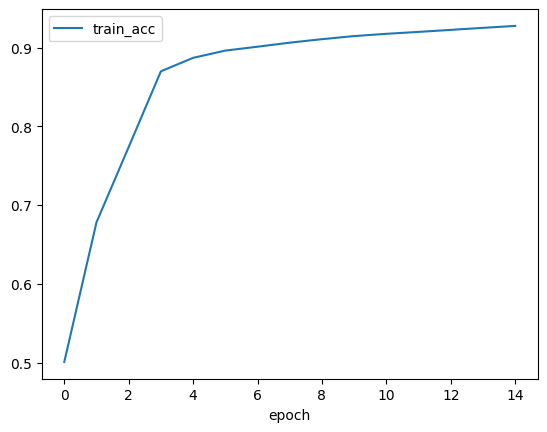

In [20]:
# 绘制训练曲线
plt.plot(range(epochs),train_acc,label='train_acc')
plt.xlabel('epoch')
plt.legend()
plt.show()